
--- Running Classification: Test Size=20.0%, Epochs=50 ---

Breast Cancer Classification Report:
               precision    recall  f1-score   support

          -1       0.92      0.96      0.94        47
           1       0.97      0.94      0.95        67

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.95       114
weighted avg       0.95      0.95      0.95       114



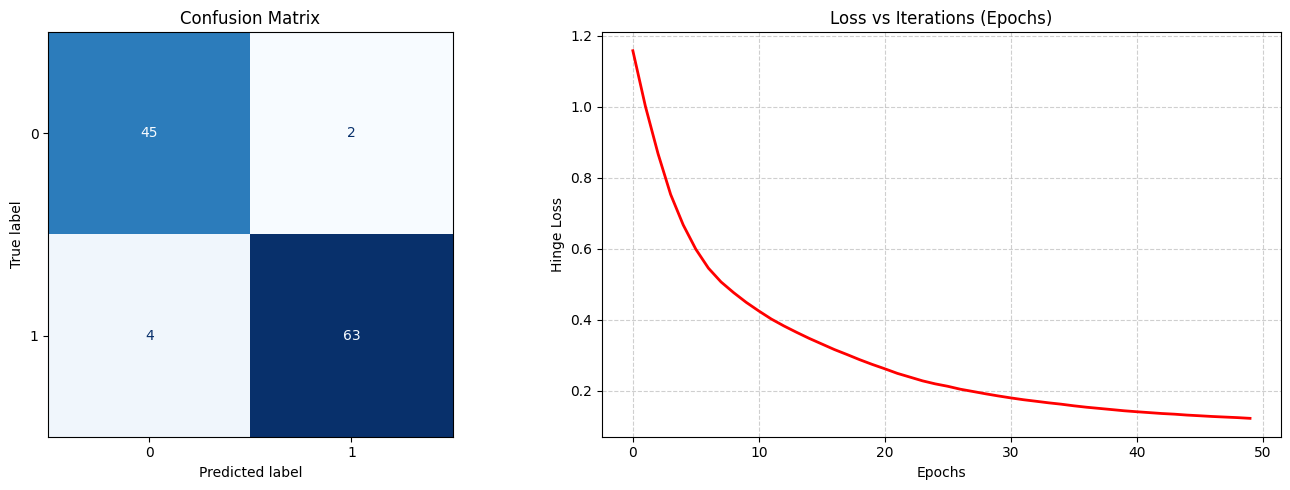


--- Running Decision Boundary: Test Size=20.0%, Epochs=50 ---



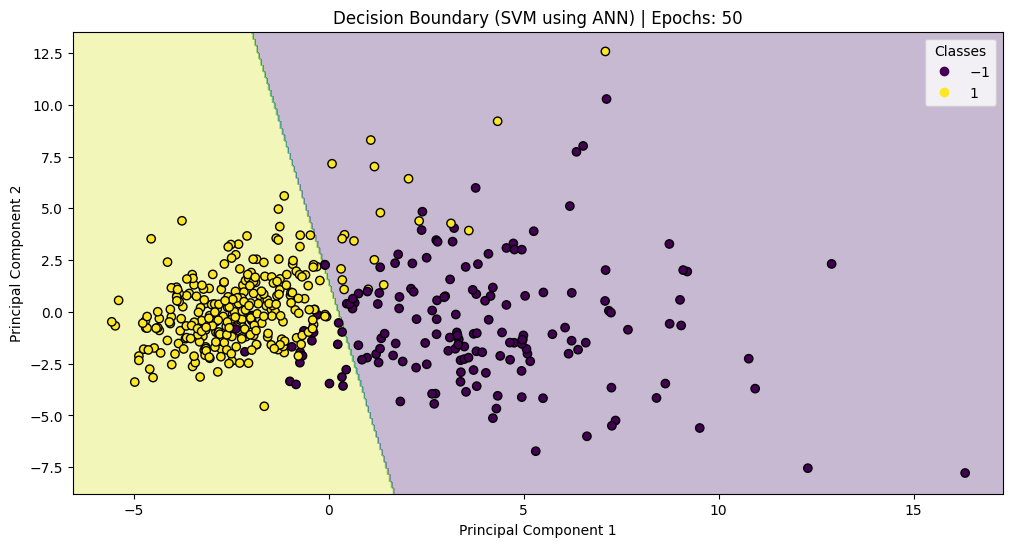

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
# -----------------------------
# Global: Define Hinge Loss
# -----------------------------
def hinge_loss(y_true, y_pred):
  # Casting to float32 to prevent dtype mismatch errors during graph execution
  y_true = tf.cast(y_true, tf.float32)
  y_pred = tf.cast(y_pred, tf.float32)
  return tf.reduce_mean(tf.maximum(0., 1. - y_true * y_pred))
# -----------------------------
# Function 1: Breast Cancer Classification
# -----------------------------
def run_svm_ann(test_size=0.2, epochs=50):
  print(f"\n--- Running Classification: Test Size={test_size*100}%, Epochs={epochs} ---\n")
  # 1. Load & Prepare Dataset
  data = datasets.load_breast_cancer()
  X = data.data
  y = np.where(data.target == 0, -1, 1)
  # 2. Train-Test Split
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=test_size, random_state=0
  )
  # 3. Feature Scaling
  sc = StandardScaler()
  X_train = sc.fit_transform(X_train)
  X_test = sc.transform(X_test)
  # 4. Build Model
  model = Sequential([
      Input(shape=(X.shape[1],)),
      Dense(1, activation='linear')
  ])
  model.compile(optimizer='adam', loss=hinge_loss, metrics=['accuracy'])
  # 5. Train Model
  history = model.fit(X_train, y_train, epochs=epochs, verbose=0)
  # 6. Predictions
  y_pred_raw = model.predict(X_test, verbose=0)
  y_pred = np.where(y_pred_raw > 0, 1, -1)
  # 7. Classification Report
  print("Breast Cancer Classification Report:\n", classification_report(y_test, y_pred))
  # 8. Side-by-Side Plots
  fig, axes = plt.subplots(1, 2, figsize=(14, 5))
  # Plot A: Confusion Matrix
  cm = confusion_matrix(y_test, y_pred)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm)
  disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
  axes[0].set_title("Confusion Matrix")
  # Plot B: Loss vs Iterations
  axes[1].plot(history.history['loss'], color='red', linewidth=2)
  axes[1].set_xlabel("Epochs")
  axes[1].set_ylabel("Hinge Loss")
  axes[1].set_title("Loss vs Iterations (Epochs)")
  axes[1].grid(True, linestyle='--', alpha=0.6)
  plt.tight_layout()
  plt.show()
# -----------------------------
# Function 2: Decision Boundary (PCA - 2D)
# -----------------------------
def run_decision_boundary(test_size=0.2, epochs=50):
  print(f"\n--- Running Decision Boundary: Test Size={test_size*100}%, Epochs={epochs} ---\n")
  # 1. Load & Prepare Dataset
  data = datasets.load_breast_cancer()
  X = data.data
  y = np.where(data.target == 0, -1, 1)
  # 2. Feature Scaling & PCA
  X_scaled = StandardScaler().fit_transform(X)
  X_pca = PCA(n_components=2).fit_transform(X_scaled)
  # 3. Train-Test Split
  X_train, X_test, y_train, y_test = train_test_split(
      X_pca, y, test_size=test_size, random_state=0
  )
  # 4. Build Model
  model = Sequential([
      Input(shape=(2,)),
      Dense(1, activation='linear')
  ])
  model.compile(optimizer='adam', loss=hinge_loss)
  # 5. Train Model
  model.fit(X_train, y_train, epochs=epochs, verbose=0)
  # 6. Plot Decision Boundary
  X1_min, X1_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
  X2_min, X2_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
  X1, X2 = np.meshgrid(np.arange(X1_min, X1_max, 0.05), np.arange(X2_min, X2_max, 0.05))
  grid = np.c_[X1.ravel(), X2.ravel()]
  Z = model.predict(grid, verbose=0)
  Z = np.where(Z > 0, 1, -1).reshape(X1.shape)
  plt.figure(figsize=(12, 6))
  plt.contourf(X1, X2, Z, alpha=0.3)
  # Scatter plot of training points
  scatter = plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolor='k')
  plt.title(f"Decision Boundary (SVM using ANN) | Epochs: {epochs}")
  plt.xlabel("Principal Component 1")
  plt.ylabel("Principal Component 2")
  # Add legend manually
  plt.legend(*scatter.legend_elements(), title="Classes")
  plt.show()
# Baseline
run_svm_ann(test_size=0.2, epochs=50)
run_decision_boundary(test_size=0.2, epochs=50)


Executing Iris SVM Classification | Test Size: 30.0%

Accuracy: 0.8000

Iris Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       0.70      0.54      0.61        13
           2       0.62      0.77      0.69        13

    accuracy                           0.80        45
   macro avg       0.78      0.77      0.77        45
weighted avg       0.81      0.80      0.80        45



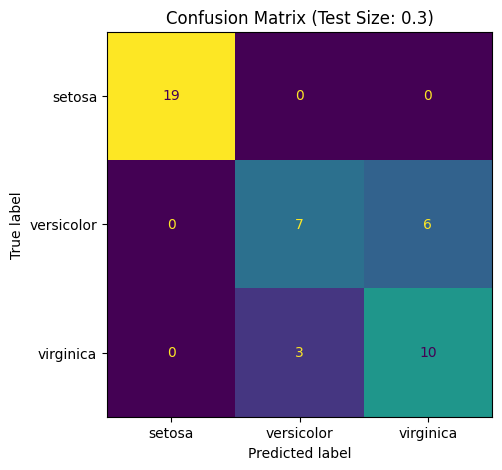

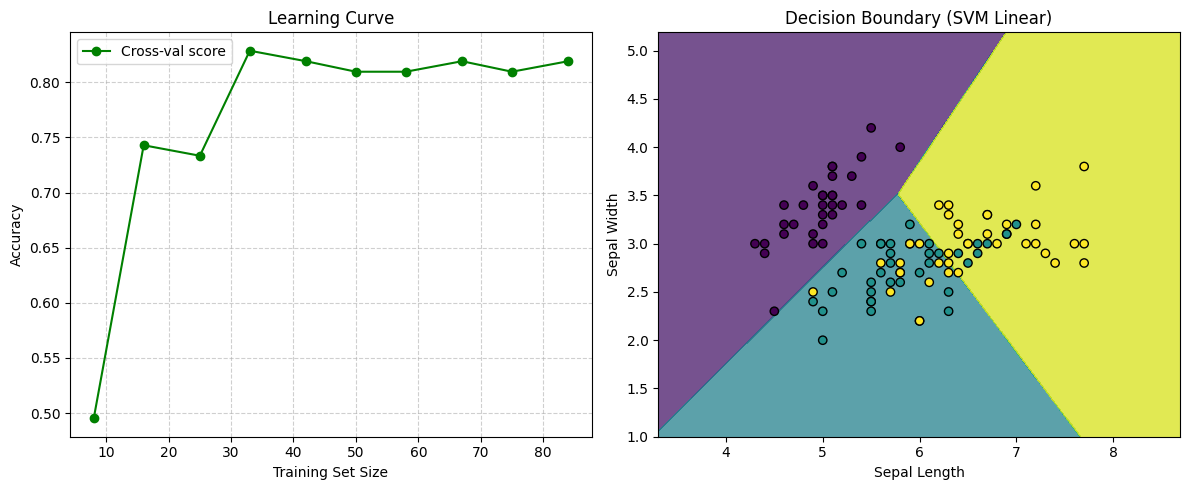

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

def run_iris_svm(test_size=0.3):
    print(f"\n{'='*50}")
    print(f"Executing Iris SVM Classification | Test Size: {test_size*100}%")
    print(f"{'='*50}\n")

    # 1. Load dataset
    iris = datasets.load_iris()
    X = iris.data[:, :2]  # Sepal length and width
    y = iris.target

    # 2. Train-Test Split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)

    # 3. Model Training
    model = SVC(kernel='linear')
    model.fit(X_train, y_train)

    # 4. Predictions & Metrics
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {acc:.4f}\n")
    print("Iris Classification Report:\n", classification_report(y_test, y_pred))

    # ---------------------------------------------------------
    # 5. Plot A: Confusion Matrix
    # ---------------------------------------------------------
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)

    fig_cm, ax_cm = plt.subplots(figsize=(5, 5))
    disp.plot(ax=ax_cm, cmap='viridis', colorbar=False)
    ax_cm.set_title(f"Confusion Matrix (Test Size: {test_size})")
    plt.show()

    # ---------------------------------------------------------
    # 6. Setup Figure for Remaining Plots (1 Row, 2 Columns)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot B: Accuracy Plot (Learning Curve)
    train_sizes_cv, train_scores, test_scores = learning_curve(
        model, X_train, y_train, cv=5, train_sizes=np.linspace(0.1, 1.0, 10)
    )
    axes[0].plot(train_sizes_cv, test_scores.mean(axis=1), 'o-', color='green', label='Cross-val score')
    axes[0].set_title("Learning Curve")
    axes[0].set_xlabel("Training Set Size")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend(loc="best")

    # Plot C: Decision Boundary
    X_set, y_set = X_train, y_train
    X1, X2 = np.meshgrid(
        np.arange(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, 0.01),
        np.arange(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, 0.01)
    )
    Z = model.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape)

    axes[1].contourf(X1, X2, Z, alpha=0.75)
    axes[1].scatter(X_set[:, 0], X_set[:, 1], c=y_set, edgecolors='k')
    axes[1].set_title("Decision Boundary (SVM Linear)")
    axes[1].set_xlabel("Sepal Length")
    axes[1].set_ylabel("Sepal Width")

    plt.tight_layout()
    plt.show()

# Baseline
run_iris_svm(test_size=0.3)


Executing Iris SVM Classification | Test Size: 20.0%

Accuracy: 0.9000

Iris Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.88      0.78      0.82         9
           2       0.83      0.91      0.87        11

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



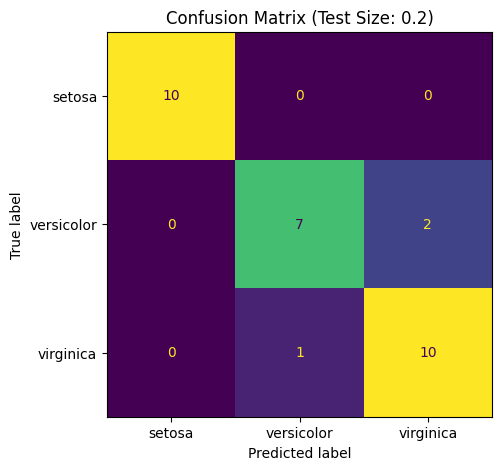

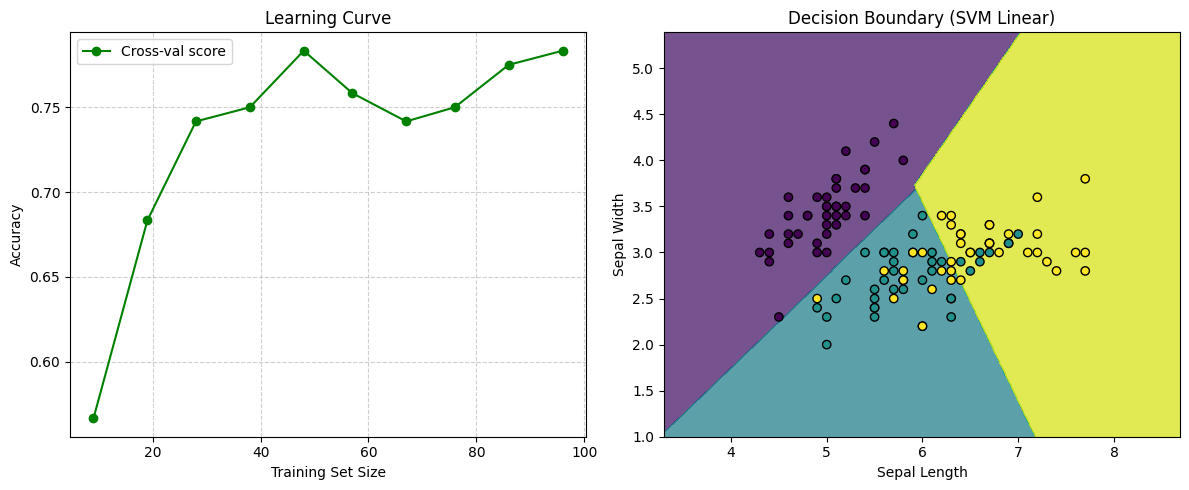

In [4]:
run_iris_svm(test_size=0.2)


Executing Digits SVM Classification | Test Size: 30.0%

Accuracy: 0.9815

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        53
           1       1.00      1.00      1.00        50
           2       0.98      1.00      0.99        47
           3       1.00      0.94      0.97        54
           4       1.00      1.00      1.00        60
           5       0.98      0.98      0.98        66
           6       0.98      0.98      0.98        53
           7       1.00      0.98      0.99        55
           8       0.91      0.98      0.94        43
           9       0.97      0.95      0.96        59

    accuracy                           0.98       540
   macro avg       0.98      0.98      0.98       540
weighted avg       0.98      0.98      0.98       540



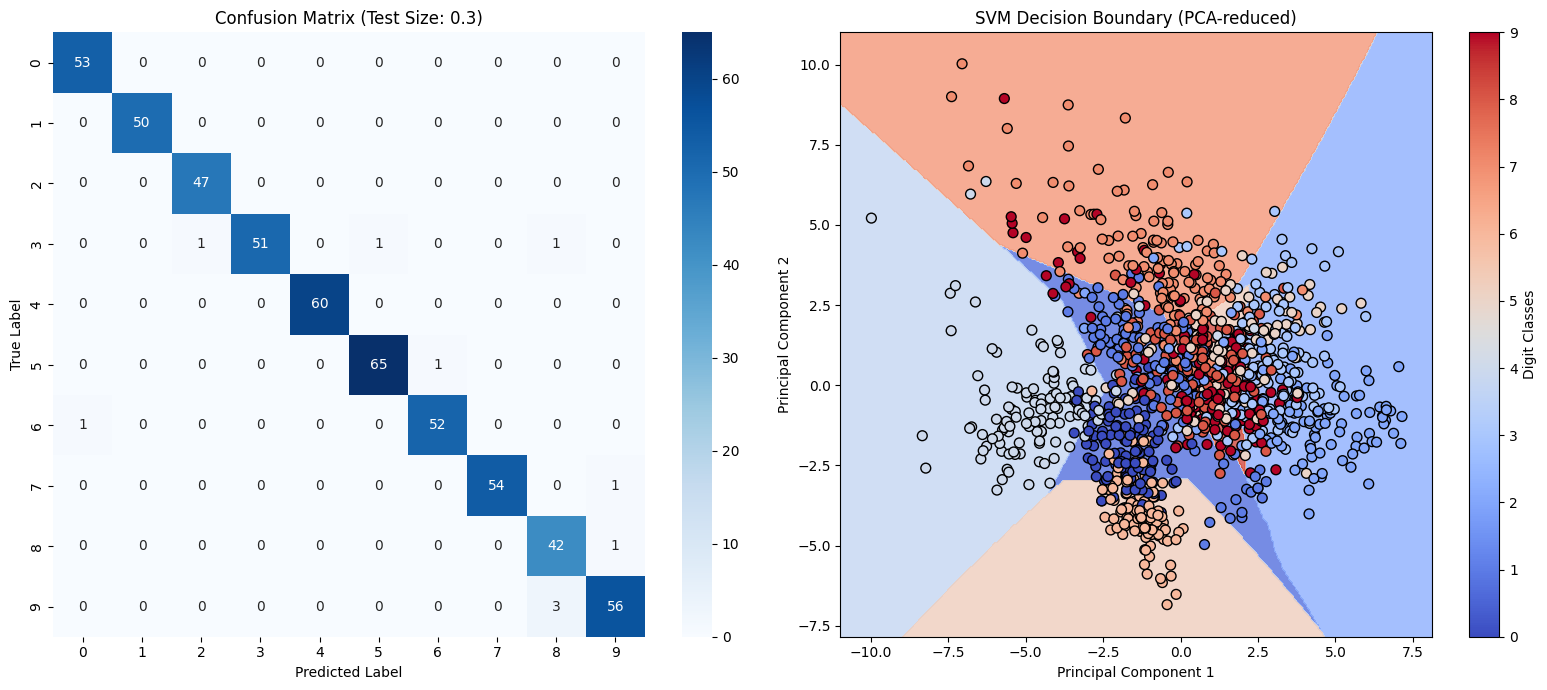

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets, svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns

def run_digits_svm(test_size=0.3):
    print(f"\n{'='*60}")
    print(f"Executing Digits SVM Classification | Test Size: {test_size*100}%")
    print(f"{'='*60}\n")

    # 1. Load the digits dataset
    digits = datasets.load_digits()
    X = digits.data
    y = digits.target

    # 2. Split the dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )

    # 3. Standardize the features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # 4. Create and train the SVM classifier (Full Data)
    clf = svm.SVC(kernel='rbf', C=10, gamma=0.001, random_state=42)
    clf.fit(X_train_scaled, y_train)

    # 5. Make predictions & Calculate metrics
    y_pred = clf.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # ---------------------------------------------------------
    # Setup Figure for Plots (1 Row, 2 Columns)
    # ---------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # Plot A: Confusion Matrix (on axes[0])
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(10), yticklabels=range(10), ax=axes[0])
    axes[0].set_xlabel('Predicted Label')
    axes[0].set_ylabel('True Label')
    axes[0].set_title(f'Confusion Matrix (Test Size: {test_size})')

    # Plot B: Decision Boundary (on axes[1])
    pca = PCA(n_components=2)
    X_train_pca = pca.fit_transform(X_train_scaled)

    # Create a mesh grid for decision boundary
    h = 0.05
    x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
    y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # Train SVM on PCA-reduced data for visualization
    clf_pca = svm.SVC(kernel='rbf', C=10, gamma=0.001, random_state=42)
    clf_pca.fit(X_train_pca, y_train)
    Z = clf_pca.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot contour and scatter on axes[1]
    axes[1].contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)
    scatter = axes[1].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train,
                             cmap=plt.cm.coolwarm, edgecolors='k', s=50)
    axes[1].set_xlabel('Principal Component 1')
    axes[1].set_ylabel('Principal Component 2')
    axes[1].set_title(f'SVM Decision Boundary (PCA-reduced)')
    fig.colorbar(scatter, ax=axes[1], ticks=range(10), label='Digit Classes')

    plt.tight_layout()
    plt.show()

# Baseline
run_digits_svm(test_size=0.3)


Executing Digits SVM Classification | Test Size: 20.0%

Accuracy: 0.9806

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      0.97      0.99        34
           4       1.00      1.00      1.00        46
           5       0.98      0.98      0.98        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       0.94      0.97      0.95        30
           9       0.95      0.95      0.95        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



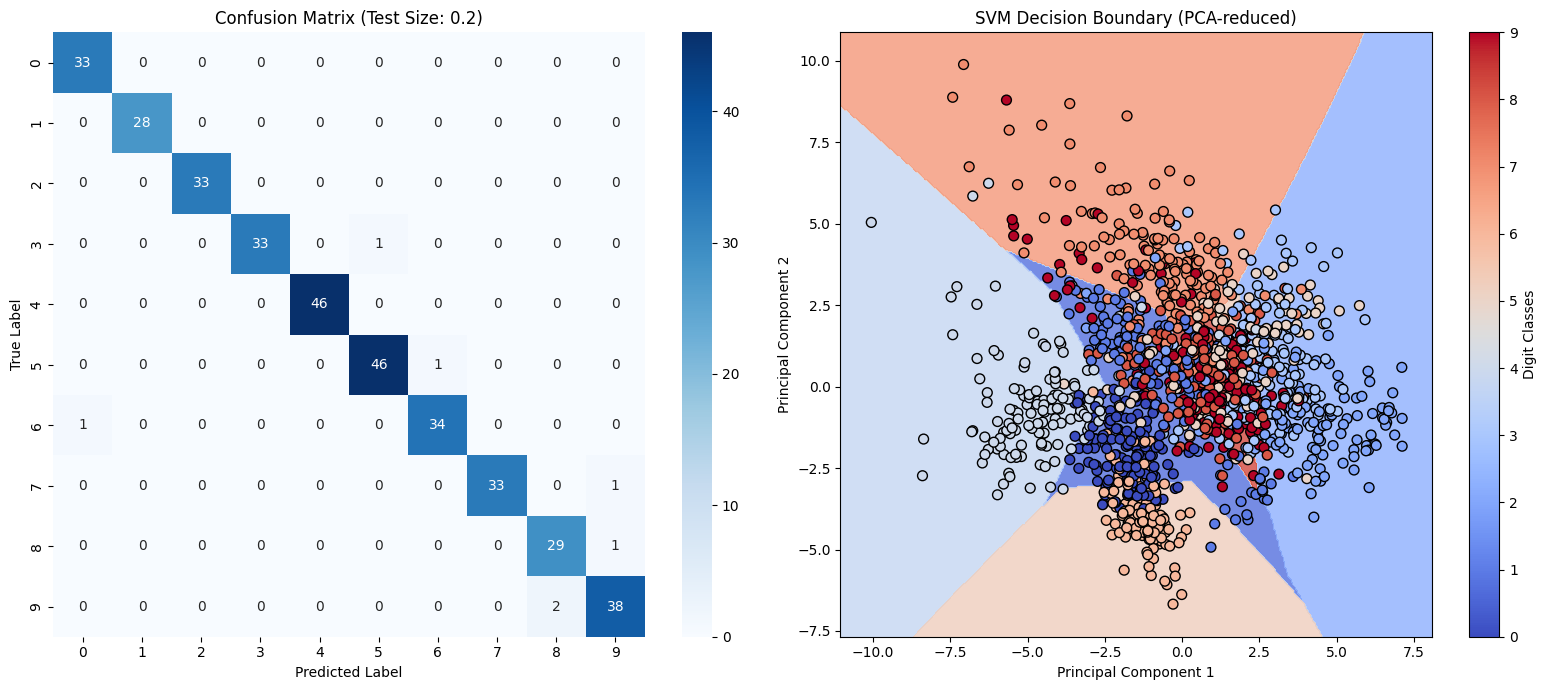

In [6]:
run_digits_svm(test_size=0.2)